In [1]:
# ============================================================================
# EJERCICIO 4: SIMULACIÓN MONTECARLO - LANZAMIENTO APP MÓVIL
# Caso Integrado - Análisis con Múltiples Variables
# ============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')

# Configuración de visualización
plt.style.use('seaborn-v0_8-whitegrid')
sns.set_palette("Set2")
np.random.seed(123)  # Para reproducibilidad

print("="*70)
print("📱 EJERCICIO 4: SIMULACIÓN MONTECARLO - APP MÓVIL")
print("="*70)
print("✅ Librerías importadas correctamente")
print("🚀 Sistema listo para simulación compleja")

📱 EJERCICIO 4: SIMULACIÓN MONTECARLO - APP MÓVIL
✅ Librerías importadas correctamente
🚀 Sistema listo para simulación compleja


In [2]:
# ============================================================================
# PARÁMETROS DEL PROYECTO
# ============================================================================

# Número de simulaciones
n_sim = 10000

# Horizonte temporal
meses_horizonte = 12

# Tasa de descuento
wacc_anual = 0.18
wacc_mensual = (1 + wacc_anual)**(1/12) - 1

print("="*70)
print("PARÁMETROS DEL PROYECTO APP MÓVIL")
print("="*70)
print(f"Simulaciones: {n_sim:,}")
print(f"Horizonte: {meses_horizonte} meses")
print(f"WACC anual: {wacc_anual:.1%}")
print(f"WACC mensual: {wacc_mensual:.4%}")
print("="*70)

# ============================================================================
# GENERAR VARIABLES ALEATORIAS
# ============================================================================

print("\n🎲 Generando variables aleatorias...")

# 1. DESCARGAS MES 1: Normal(media=5000, desv=1200)
descargas_mes1 = np.random.normal(loc=5000, scale=1200, size=n_sim)
descargas_mes1 = np.maximum(descargas_mes1, 1000)  # Mínimo razonable

# 2. TASA CONVERSIÓN A PAGO: Triangular(min=2%, moda=4%, max=7%)
tasa_conversion = np.random.triangular(left=0.02, mode=0.04, right=0.07, size=n_sim)

# 3. PRECIO SUSCRIPCIÓN: Normal(media=$9.99, desv=$1.50)
precio_suscripcion = np.random.normal(loc=9.99, scale=1.50, size=n_sim)
precio_suscripcion = np.maximum(precio_suscripcion, 4.99)  # Mínimo $4.99

# 4. CHURN MENSUAL: Uniforme(10%, 20%)
churn_mensual = np.random.uniform(low=0.10, high=0.20, size=n_sim)

# 5. CAPEX DESARROLLO: Normal(media=$120K, desv=$18K)
capex_desarrollo = np.random.normal(loc=120000, scale=18000, size=n_sim)
capex_desarrollo = np.maximum(capex_desarrollo, 80000)  # Mínimo $80K

# Costos fijos mensuales (asumidos constantes)
opex_mensual_fijo = 8000  # $8,000/mes

print("✅ Variables aleatorias generadas:")
print(f"   1. Descargas mes 1: {len(descargas_mes1):,} escenarios")
print(f"   2. Tasa conversión: {len(tasa_conversion):,} escenarios")
print(f"   3. Precio suscripción: {len(precio_suscripcion):,} escenarios")
print(f"   4. Churn mensual: {len(churn_mensual):,} escenarios")
print(f"   5. CAPEX desarrollo: {len(capex_desarrollo):,} escenarios")

# Mostrar estadísticas de inputs
print("\n📊 ESTADÍSTICAS DE INPUTS:")
print(f"   Descargas mes 1:     Media={descargas_mes1.mean():.0f}, σ={descargas_mes1.std():.0f}")
print(f"   Tasa conversión:     Media={tasa_conversion.mean():.2%}, σ={tasa_conversion.std():.2%}")
print(f"   Precio suscripción:  Media=${precio_suscripcion.mean():.2f}, σ=${precio_suscripcion.std():.2f}")
print(f"   Churn mensual:       Media={churn_mensual.mean():.2%}, σ={churn_mensual.std():.2%}")
print(f"   CAPEX desarrollo:    Media=${capex_desarrollo.mean():,.0f}, σ=${capex_desarrollo.std():,.0f}")

PARÁMETROS DEL PROYECTO APP MÓVIL
Simulaciones: 10,000
Horizonte: 12 meses
WACC anual: 18.0%
WACC mensual: 1.3888%

🎲 Generando variables aleatorias...
✅ Variables aleatorias generadas:
   1. Descargas mes 1: 10,000 escenarios
   2. Tasa conversión: 10,000 escenarios
   3. Precio suscripción: 10,000 escenarios
   4. Churn mensual: 10,000 escenarios
   5. CAPEX desarrollo: 10,000 escenarios

📊 ESTADÍSTICAS DE INPUTS:
   Descargas mes 1:     Media=5012, σ=1197
   Tasa conversión:     Media=4.35%, σ=1.02%
   Precio suscripción:  Media=$9.97, σ=$1.49
   Churn mensual:       Media=15.05%, σ=2.88%
   CAPEX desarrollo:    Media=$120,164, σ=$17,718


In [3]:
# ============================================================================
# MODELO DE PROYECCIÓN A 12 MESES
# ============================================================================

print("\n🔄 Ejecutando simulación de 12 meses...")
print("   (Esto puede tomar unos segundos...)")

# Matrices para almacenar resultados
usuarios_activos = np.zeros((n_sim, meses_horizonte + 1))
ingresos_mensuales = np.zeros((n_sim, meses_horizonte))
flujos_caja = np.zeros((n_sim, meses_horizonte + 1))

# Inicializar mes 0
for i in range(n_sim):
    # Inversión inicial (CAPEX)
    flujos_caja[i, 0] = -capex_desarrollo[i]

    # Usuarios iniciales mes 1
    nuevos_usuarios_mes1 = descargas_mes1[i] * tasa_conversion[i]
    usuarios_activos[i, 1] = nuevos_usuarios_mes1

# Proyección mensual
for t in range(1, meses_horizonte + 1):
    for i in range(n_sim):
        # Usuarios activos al inicio del mes
        if t == 1:
            usuarios_mes = usuarios_activos[i, 1]
        else:
            # Usuarios previos menos churn + nuevos (crecimiento 5% en descargas)
            usuarios_previos = usuarios_activos[i, t-1] * (1 - churn_mensual[i])
            factor_crecimiento = 1.05  # Crecimiento orgánico 5%/mes
            nuevas_descargas = descargas_mes1[i] * factor_crecimiento**(t-1)
            nuevos_usuarios = nuevas_descargas * tasa_conversion[i]
            usuarios_mes = usuarios_previos + nuevos_usuarios
            usuarios_activos[i, t] = usuarios_mes

        # Ingresos del mes
        ingresos = usuarios_mes * precio_suscripcion[i]
        ingresos_mensuales[i, t-1] = ingresos

        # Flujo de caja del mes (Ingresos - OPEX fijo)
        fcf_mes = ingresos - opex_mensual_fijo

        if t <= meses_horizonte:
            flujos_caja[i, t] = fcf_mes

# ============================================================================
# CALCULAR VPN PARA CADA SIMULACIÓN
# ============================================================================

vpn_simulaciones = np.zeros(n_sim)

for i in range(n_sim):
    vpn = flujos_caja[i, 0]  # Inversión inicial (negativa)

    for t in range(1, meses_horizonte + 1):
        vpn += flujos_caja[i, t] / (1 + wacc_mensual)**t

    vpn_simulaciones[i] = vpn

print(f"✅ Simulación completada: {n_sim:,} escenarios proyectados a {meses_horizonte} meses")
print(f"\nPrimeros 5 resultados VPN:")
for i in range(5):
    print(f"   Escenario {i+1}: ${vpn_simulaciones[i]:,.0f}")


🔄 Ejecutando simulación de 12 meses...
   (Esto puede tomar unos segundos...)
✅ Simulación completada: 10,000 escenarios proyectados a 12 meses

Primeros 5 resultados VPN:
   Escenario 1: $-70,026
   Escenario 2: $35,338
   Escenario 3: $-53,543
   Escenario 4: $-155,061
   Escenario 5: $-108,149


In [4]:
# ============================================================================
# ESTADÍSTICAS DESCRIPTIVAS Y MÉTRICAS DE RIESGO
# ============================================================================

# Estadísticas básicas
media_vpn = vpn_simulaciones.mean()
mediana_vpn = np.median(vpn_simulaciones)
desv_vpn = vpn_simulaciones.std()
min_vpn = vpn_simulaciones.min()
max_vpn = vpn_simulaciones.max()
cv = desv_vpn / media_vpn if media_vpn != 0 else np.inf

# Percentiles
percentiles = [5, 10, 25, 50, 75, 90, 95]
valores_percentiles = np.percentile(vpn_simulaciones, percentiles)

# Probabilidad de éxito
prob_vpn_positivo = (vpn_simulaciones > 0).sum() / n_sim * 100

# VaR y CVaR
var_95 = np.percentile(vpn_simulaciones, 5)
cvar_95 = vpn_simulaciones[vpn_simulaciones <= var_95].mean()

# Ingresos promedio y usuarios promedio en mes 12
ingresos_mes12 = ingresos_mensuales[:, -1]
usuarios_mes12 = usuarios_activos[:, -1]

# ============================================================================
# REPORTE COMPLETO
# ============================================================================

print("\n" + "="*80)
print("📊 RESULTADOS ANÁLISIS MONTECARLO - APP MÓVIL")
print("="*80)

print(f"\n🎯 ESTADÍSTICAS DEL VPN:")
print(f"   E(VPN) - Valor Esperado:           ${media_vpn:>15,.0f}")
print(f"   Mediana:                           ${mediana_vpn:>15,.0f}")
print(f"   Desviación Estándar:               ${desv_vpn:>15,.0f}")
print(f"   Coeficiente de Variación (CV):     {cv:>18.3f}")

print(f"\n📏 RANGO DE RESULTADOS:")
print(f"   VPN Mínimo:                        ${min_vpn:>15,.0f}")
print(f"   VPN Máximo:                        ${max_vpn:>15,.0f}")
print(f"   Amplitud (Rango):                  ${max_vpn - min_vpn:>15,.0f}")

print(f"\n📈 DISTRIBUCIÓN DE PERCENTILES:")
for p, val in zip(percentiles, valores_percentiles):
    print(f"   P{p:02d}:                                  ${val:>15,.0f}")

print(f"\n⚠️ MÉTRICAS DE RIESGO:")
print(f"   Probabilidad VPN > 0:              {prob_vpn_positivo:>18.2f}%")
print(f"   Value at Risk (VaR 95%):           ${var_95:>15,.0f}")
print(f"   CVaR 95% (Expected Shortfall):     ${cvar_95:>15,.0f}")

print(f"\n👥 MÉTRICAS OPERATIVAS (Mes 12):")
print(f"   Usuarios activos promedio:         {usuarios_mes12.mean():>18,.0f}")
print(f"   Ingresos mensuales promedio:       ${ingresos_mes12.mean():>15,.0f}")
print(f"   MRR (Monthly Recurring Revenue):   ${ingresos_mes12.mean():>15,.0f}")

print(f"\n💡 RECOMENDACIÓN:")
if prob_vpn_positivo >= 70 and cv < 1.5:
    decision = "✅ GO - Proyecto viable con riesgo aceptable"
elif prob_vpn_positivo >= 50:
    decision = "⚠️ CONDITIONAL - Requiere plan de mitigación de riesgos"
else:
    decision = "❌ NO-GO - Proyecto demasiado riesgoso"

print(f"   {decision}")
print(f"   Nivel de confianza: {prob_vpn_positivo:.1f}%")
print(f"   Valoración de riesgo: {'BAJO' if cv < 0.8 else 'MODERADO' if cv < 1.5 else 'ALTO'} (CV={cv:.2f})")

print("\n" + "="*80)

# DataFrame de resumen
resumen_df = pd.DataFrame({
    'Métrica': ['E(VPN)', 'Mediana VPN', 'Desv. Estándar', 'CV', 'VPN Min', 'VPN Max',
                'P05', 'P50', 'P95', 'Prob(VPN>0)', 'VaR 95%', 'CVaR 95%',
                'Usuarios Mes 12', 'Ingresos Mes 12'],
    'Valor': [f'${media_vpn:,.0f}', f'${mediana_vpn:,.0f}', f'${desv_vpn:,.0f}',
              f'{cv:.3f}', f'${min_vpn:,.0f}', f'${max_vpn:,.0f}',
              f'${valores_percentiles[0]:,.0f}', f'${valores_percentiles[3]:,.0f}',
              f'${valores_percentiles[6]:,.0f}', f'{prob_vpn_positivo:.2f}%',
              f'${var_95:,.0f}', f'${cvar_95:,.0f}',
              f'{usuarios_mes12.mean():,.0f}', f'${ingresos_mes12.mean():,.0f}']
})

print("\n📋 TABLA RESUMEN:")
print(resumen_df.to_string(index=False))


📊 RESULTADOS ANÁLISIS MONTECARLO - APP MÓVIL

🎯 ESTADÍSTICAS DEL VPN:
   E(VPN) - Valor Esperado:           $        -92,425
   Mediana:                           $        -97,283
   Desviación Estándar:               $         47,690
   Coeficiente de Variación (CV):                 -0.516

📏 RANGO DE RESULTADOS:
   VPN Mínimo:                        $       -225,421
   VPN Máximo:                        $        133,652
   Amplitud (Rango):                  $        359,073

📈 DISTRIBUCIÓN DE PERCENTILES:
   P05:                                  $       -161,714
   P10:                                  $       -149,186
   P25:                                  $       -126,286
   P50:                                  $        -97,283
   P75:                                  $        -63,778
   P90:                                  $        -29,062
   P95:                                  $         -6,253

⚠️ MÉTRICAS DE RIESGO:
   Probabilidad VPN > 0:                            4.05

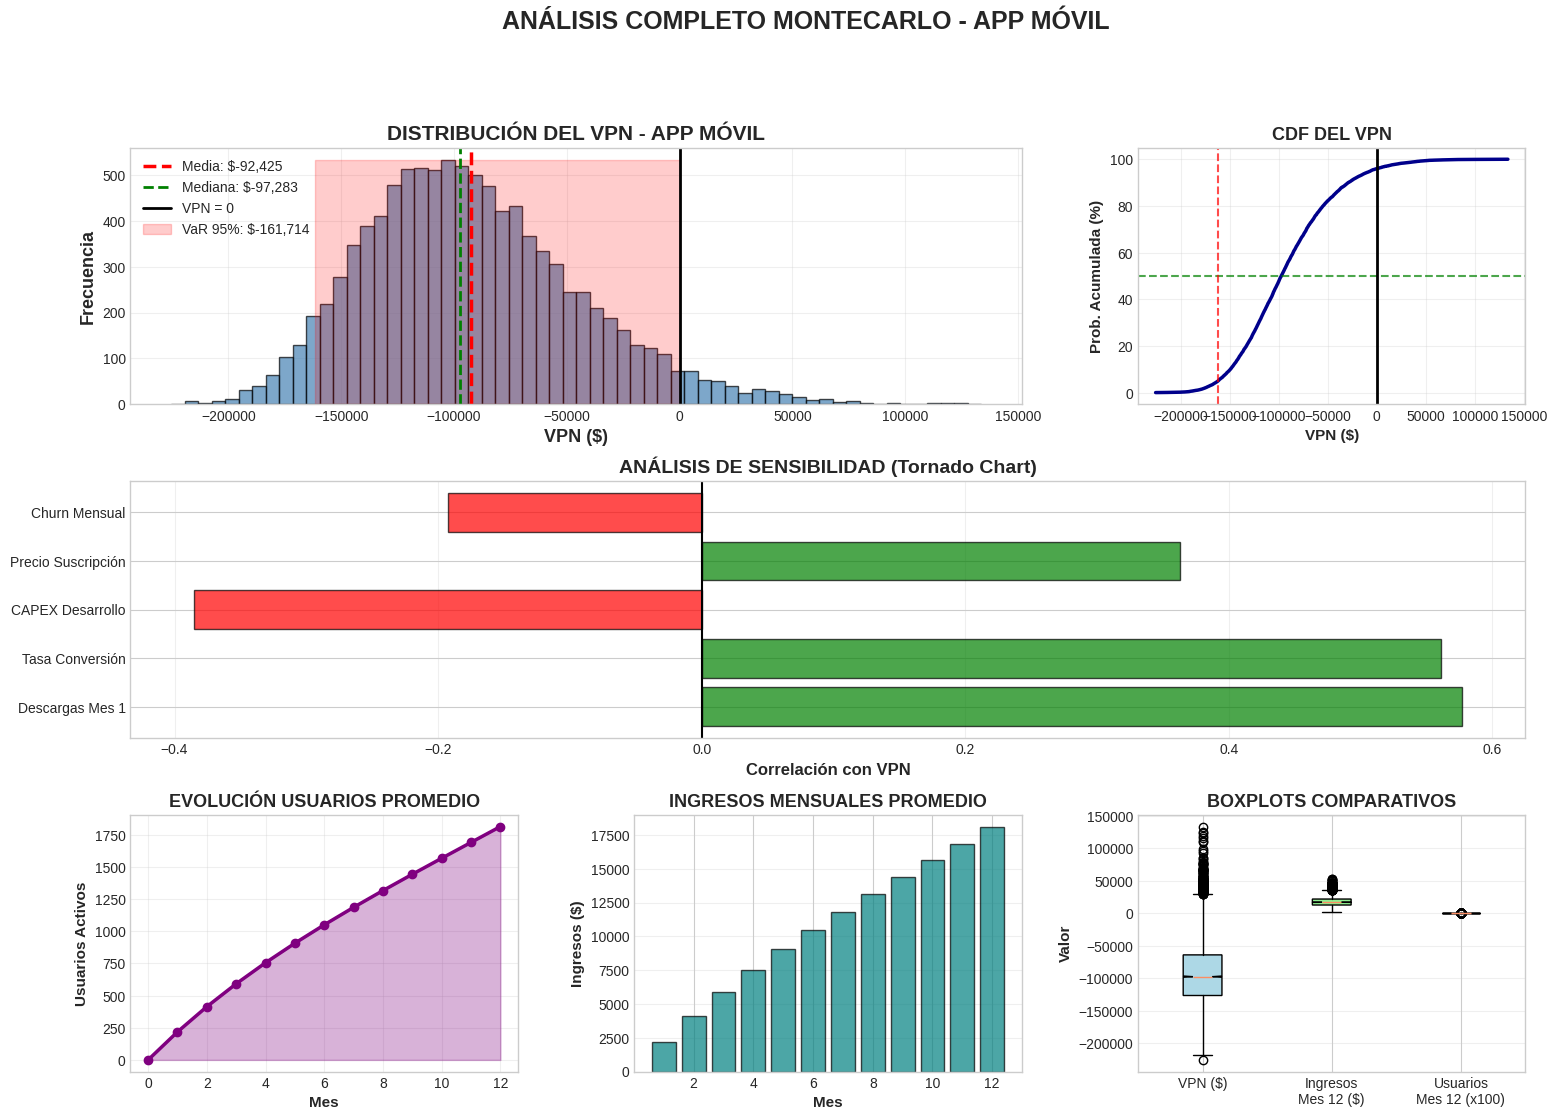

✅ Visualizaciones generadas correctamente

🎉 ANÁLISIS COMPLETO FINALIZADO


In [5]:
# ============================================================================
# VISUALIZACIONES COMPLETAS
# ============================================================================

fig = plt.figure(figsize=(18, 12))
gs = fig.add_gridspec(3, 3, hspace=0.3, wspace=0.3)

# --- GRÁFICO 1: Histograma VPN ---
ax1 = fig.add_subplot(gs[0, :2])
n, bins, patches = ax1.hist(vpn_simulaciones, bins=60, alpha=0.7, color='steelblue', edgecolor='black')
ax1.axvline(media_vpn, color='red', linestyle='--', linewidth=2.5, label=f'Media: ${media_vpn:,.0f}')
ax1.axvline(mediana_vpn, color='green', linestyle='--', linewidth=2, label=f'Mediana: ${mediana_vpn:,.0f}')
ax1.axvline(0, color='black', linestyle='-', linewidth=2, label='VPN = 0')
ax1.fill_betweenx([0, max(n)], var_95, 0, alpha=0.2, color='red', label=f'VaR 95%: ${var_95:,.0f}')
ax1.set_xlabel('VPN ($)', fontsize=13, fontweight='bold')
ax1.set_ylabel('Frecuencia', fontsize=13, fontweight='bold')
ax1.set_title('DISTRIBUCIÓN DEL VPN - APP MÓVIL', fontsize=15, fontweight='bold')
ax1.legend(fontsize=10, loc='upper left')
ax1.grid(True, alpha=0.3)

# --- GRÁFICO 2: Distribución acumulada ---
ax2 = fig.add_subplot(gs[0, 2])
sorted_vpn = np.sort(vpn_simulaciones)
cumulative = np.arange(1, len(sorted_vpn) + 1) / len(sorted_vpn) * 100
ax2.plot(sorted_vpn, cumulative, color='darkblue', linewidth=2.5)
ax2.axhline(50, color='green', linestyle='--', alpha=0.7)
ax2.axvline(0, color='black', linestyle='-', linewidth=2)
ax2.axvline(var_95, color='red', linestyle='--', alpha=0.7)
ax2.set_xlabel('VPN ($)', fontsize=11, fontweight='bold')
ax2.set_ylabel('Prob. Acumulada (%)', fontsize=11, fontweight='bold')
ax2.set_title('CDF DEL VPN', fontsize=13, fontweight='bold')
ax2.grid(True, alpha=0.3)

# --- GRÁFICO 3: Tornado chart (sensibilidad) ---
ax3 = fig.add_subplot(gs[1, :])

# Calcular correlaciones
corr_descargas = np.corrcoef(descargas_mes1, vpn_simulaciones)[0, 1]
corr_conversion = np.corrcoef(tasa_conversion, vpn_simulaciones)[0, 1]
corr_precio = np.corrcoef(precio_suscripcion, vpn_simulaciones)[0, 1]
corr_churn = np.corrcoef(churn_mensual, vpn_simulaciones)[0, 1]
corr_capex = np.corrcoef(capex_desarrollo, vpn_simulaciones)[0, 1]

variables = ['Descargas Mes 1', 'Tasa Conversión', 'Precio Suscripción', 'Churn Mensual', 'CAPEX Desarrollo']
correlaciones = [corr_descargas, corr_conversion, corr_precio, corr_churn, corr_capex]

# Ordenar por valor absoluto
indices_ordenados = np.argsort(np.abs(correlaciones))[::-1]
variables_ordenadas = [variables[i] for i in indices_ordenados]
correlaciones_ordenadas = [correlaciones[i] for i in indices_ordenados]

colors = ['green' if c > 0 else 'red' for c in correlaciones_ordenadas]
ax3.barh(variables_ordenadas, correlaciones_ordenadas, color=colors, alpha=0.7, edgecolor='black')
ax3.axvline(0, color='black', linewidth=1.5)
ax3.set_xlabel('Correlación con VPN', fontsize=12, fontweight='bold')
ax3.set_title('ANÁLISIS DE SENSIBILIDAD (Tornado Chart)', fontsize=14, fontweight='bold')
ax3.grid(True, alpha=0.3, axis='x')

# --- GRÁFICO 4: Evolución de usuarios promedio ---
ax4 = fig.add_subplot(gs[2, 0])
usuarios_promedio_por_mes = usuarios_activos.mean(axis=0)
meses_eje = np.arange(0, meses_horizonte + 1)
ax4.plot(meses_eje, usuarios_promedio_por_mes, marker='o', linewidth=2.5, color='purple', markersize=6)
ax4.fill_between(meses_eje, usuarios_promedio_por_mes, alpha=0.3, color='purple')
ax4.set_xlabel('Mes', fontsize=11, fontweight='bold')
ax4.set_ylabel('Usuarios Activos', fontsize=11, fontweight='bold')
ax4.set_title('EVOLUCIÓN USUARIOS PROMEDIO', fontsize=13, fontweight='bold')
ax4.grid(True, alpha=0.3)

# --- GRÁFICO 5: Ingresos mensuales promedio ---
ax5 = fig.add_subplot(gs[2, 1])
ingresos_promedio_por_mes = ingresos_mensuales.mean(axis=0)
ax5.bar(range(1, meses_horizonte + 1), ingresos_promedio_por_mes, color='teal', alpha=0.7, edgecolor='black')
ax5.set_xlabel('Mes', fontsize=11, fontweight='bold')
ax5.set_ylabel('Ingresos ($)', fontsize=11, fontweight='bold')
ax5.set_title('INGRESOS MENSUALES PROMEDIO', fontsize=13, fontweight='bold')
ax5.grid(True, alpha=0.3, axis='y')

# --- GRÁFICO 6: Boxplot comparativo ---
ax6 = fig.add_subplot(gs[2, 2])
data_box = [vpn_simulaciones, ingresos_mes12, usuarios_mes12/100]  # Escalado para visualización
bp = ax6.boxplot(data_box, labels=['VPN ($)', 'Ingresos\nMes 12 ($)', 'Usuarios\nMes 12 (x100)'],
                 patch_artist=True, notch=True)
for patch, color in zip(bp['boxes'], ['lightblue', 'lightgreen', 'lightyellow']):
    patch.set_facecolor(color)
ax6.set_ylabel('Valor', fontsize=11, fontweight='bold')
ax6.set_title('BOXPLOTS COMPARATIVOS', fontsize=13, fontweight='bold')
ax6.grid(True, alpha=0.3, axis='y')

plt.suptitle('ANÁLISIS COMPLETO MONTECARLO - APP MÓVIL', fontsize=18, fontweight='bold', y=0.995)
plt.show()

print("✅ Visualizaciones generadas correctamente")
print("\n🎉 ANÁLISIS COMPLETO FINALIZADO")